<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Homeworks/HW2_kNN_LinReg_GT25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашка 2. k-Nearest Neighbors and Linear Regression

### imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor as kNN
from sklearn.linear_model import LinearRegression as LinReg
from sklearn.linear_model import RidgeCV

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline

### Заметка про пайплайны

В `sklearn` можно объединить предобработку данных и обучение модели в единый объект — `Pipeline`. Иногда это упрощает код. Например, полиномиальную регрессию (линейную регрессию с предварительным добавлением признаков, возведенных в степени от 2 до *n*) можно оформить так:

In [2]:
pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=3)),
    ('scale', StandardScaler()),
    ('reg', LinReg()),
])

`Pipeline` по умолчанию принимает список кортежей — имя шага и соответствующий объект. Эти объекты применяются к данным последовательно, в порядке их указания: вывод одного шага становится входом следующего. У `Pipeline` есть методы `.fit` и `.predict`, так что его можно использовать как обычную модель.

## Задача 1. Визуальная оценка

### Генерация данных

В этой задаче мы не будем делить данные на обучающую и тестовую выборки и считать метрики качества. Вместо этого оценим модели визуально, чтобы развить интуицию о том, как они работают. Для начала сгенерируем интересную функцию.

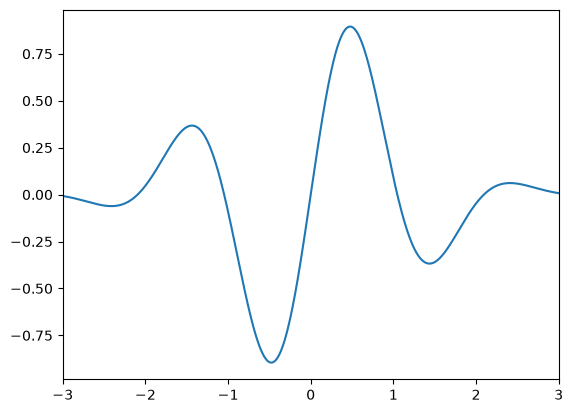

In [3]:
f = lambda x: np.sin(3*x) * np.exp(-(x/1.5)**2)

x = np.arange(-3, 3.01, 0.01)
y = f(x)

plt.plot(x, y)
plt.xlim([-3, 3])
plt.show()

Для обучения возьмем случайные точки из нужного диапазона и добавим к ним нормальный шум — реальные данные почти всегда содержат погрешности.

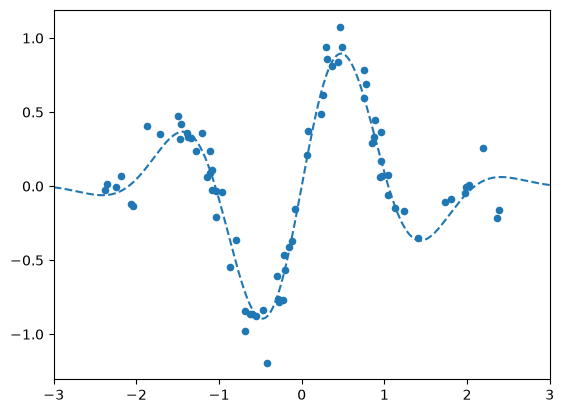

In [4]:
n_points = 75
np.random.seed(3)


x_train = np.random.uniform(-2.5, 2.51, n_points)
y_train = f(x_train) + np.random.normal(0, 0.15, n_points)

plt.plot(x, y, '--')
plt.scatter(x_train, y_train, s=20)

plt.xlim([-3, 3])
plt.show()

### Ваше решение

Осуществите предсказания методами kNN и полиномиальной регрессии (в последнем случае используйте `RidgeCV` как финальный шаг пайплайна). Обучайте модели строго на `x_train`. Визуализируйте результаты предсказаний на полном диапазоне `x`, добавив на график исходную функцию (`plt.plot(x, y)`) и обучающие точки (`plt.scatter(x_train, y_train)`). Подберите число ближайших соседей и степень полинома на глаз.

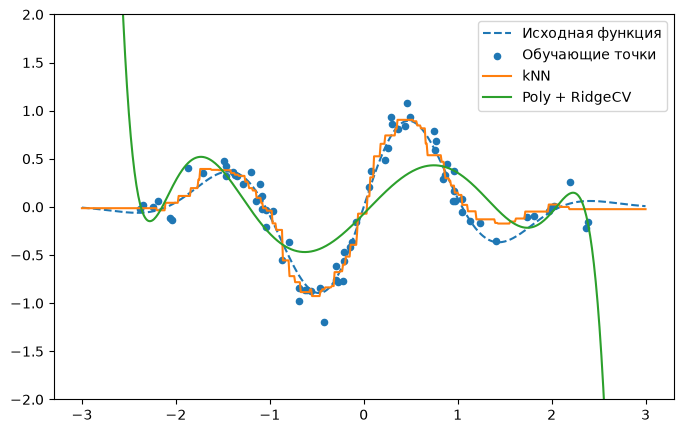

In [5]:
# your code here

pipe_KNN = Pipeline([
    ('scale', StandardScaler()),
    ('reg', kNN(n_neighbors=5))
    ])


pipe_KNN.fit(x_train.reshape(-1, 1), y_train)

y_knn_pred = pipe_KNN.predict(x.reshape(-1, 1))




pipe_pr = Pipeline([
    ('poly', PolynomialFeatures(degree=12)),
    ('scale', StandardScaler()),
    ('reg', RidgeCV()),
])

pipe_pr.fit(x_train.reshape(-1, 1), y_train)
y_pr_pred = pipe_pr.predict(x.reshape(-1, 1))


plt.figure(figsize=(8, 5))
plt.plot(x, y, '--', label='Исходная функция')
plt.scatter(x_train, y_train, s=20, label='Обучающие точки')
plt.plot(x, y_knn_pred, label='kNN')
plt.plot(x, y_pr_pred, label='Poly + RidgeCV')
plt.ylim([-2, 2])
plt.legend()
plt.show()

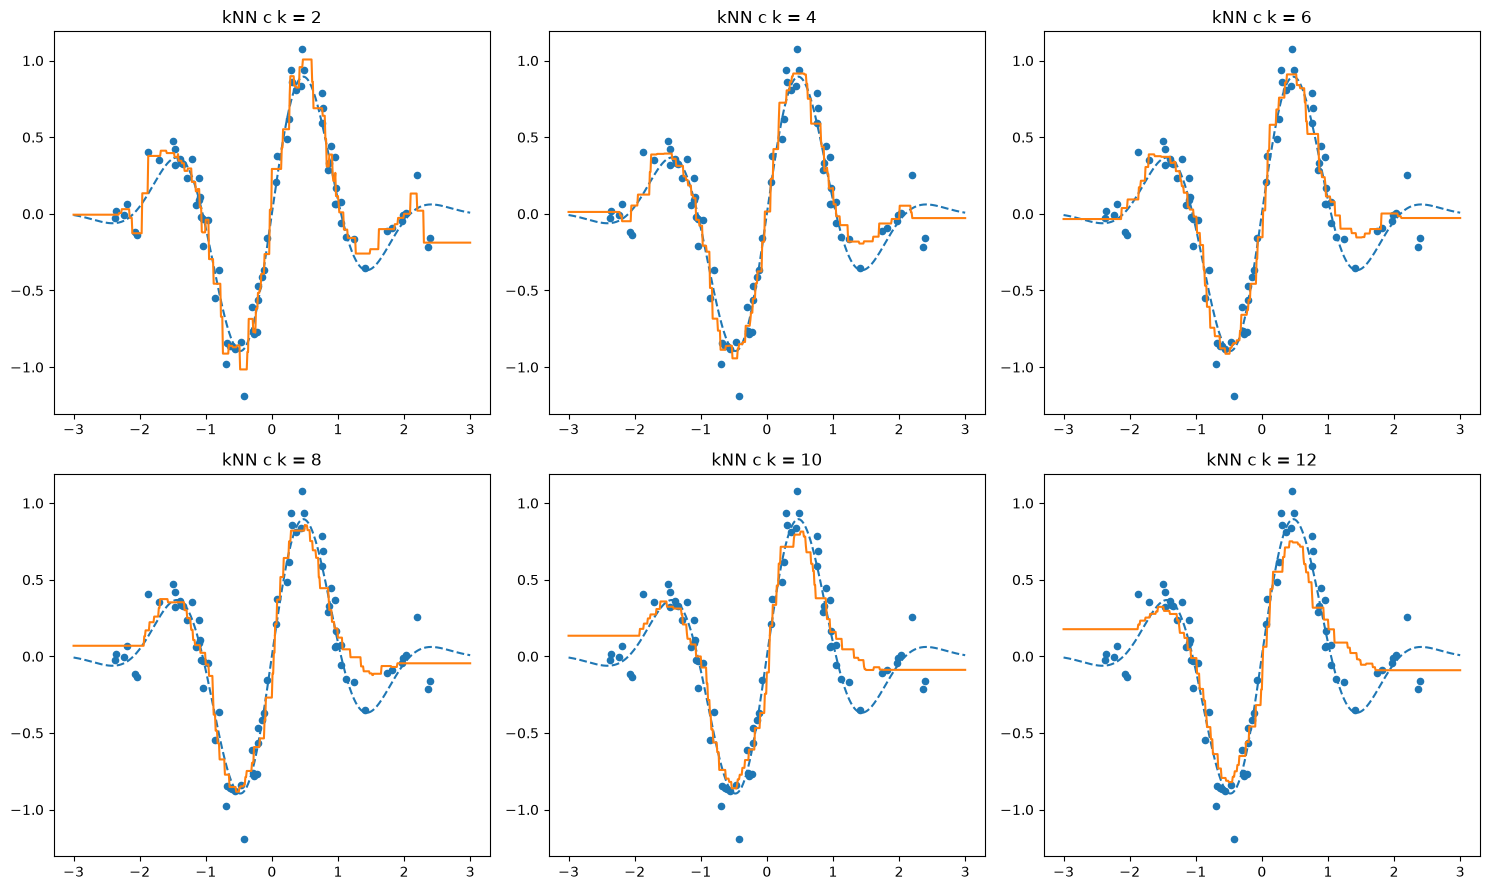

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
k_list = [i for i in range(2, 13, 2)]


for n, k in enumerate(k_list):
    j = n%3
    i = n//3
    
    pipe_KNN = Pipeline([
    ('scale', StandardScaler()),
    ('reg', kNN(n_neighbors=k))
    ])

    pipe_KNN.fit(x_train.reshape(-1, 1), y_train)
    y_knn_pred = pipe_KNN.predict(x.reshape(-1, 1))
    
    axes[i, j].plot(x, y, '--', label='Исходная функция')
    axes[i, j].scatter(x_train, y_train, s=20, label='Обучающие точки')
    axes[i, j].plot(x, y_knn_pred, label=f'kNN с k = {k}')
    axes[i, j].set_title(f'kNN с k = {k}')
    fig.tight_layout()


plt.show()

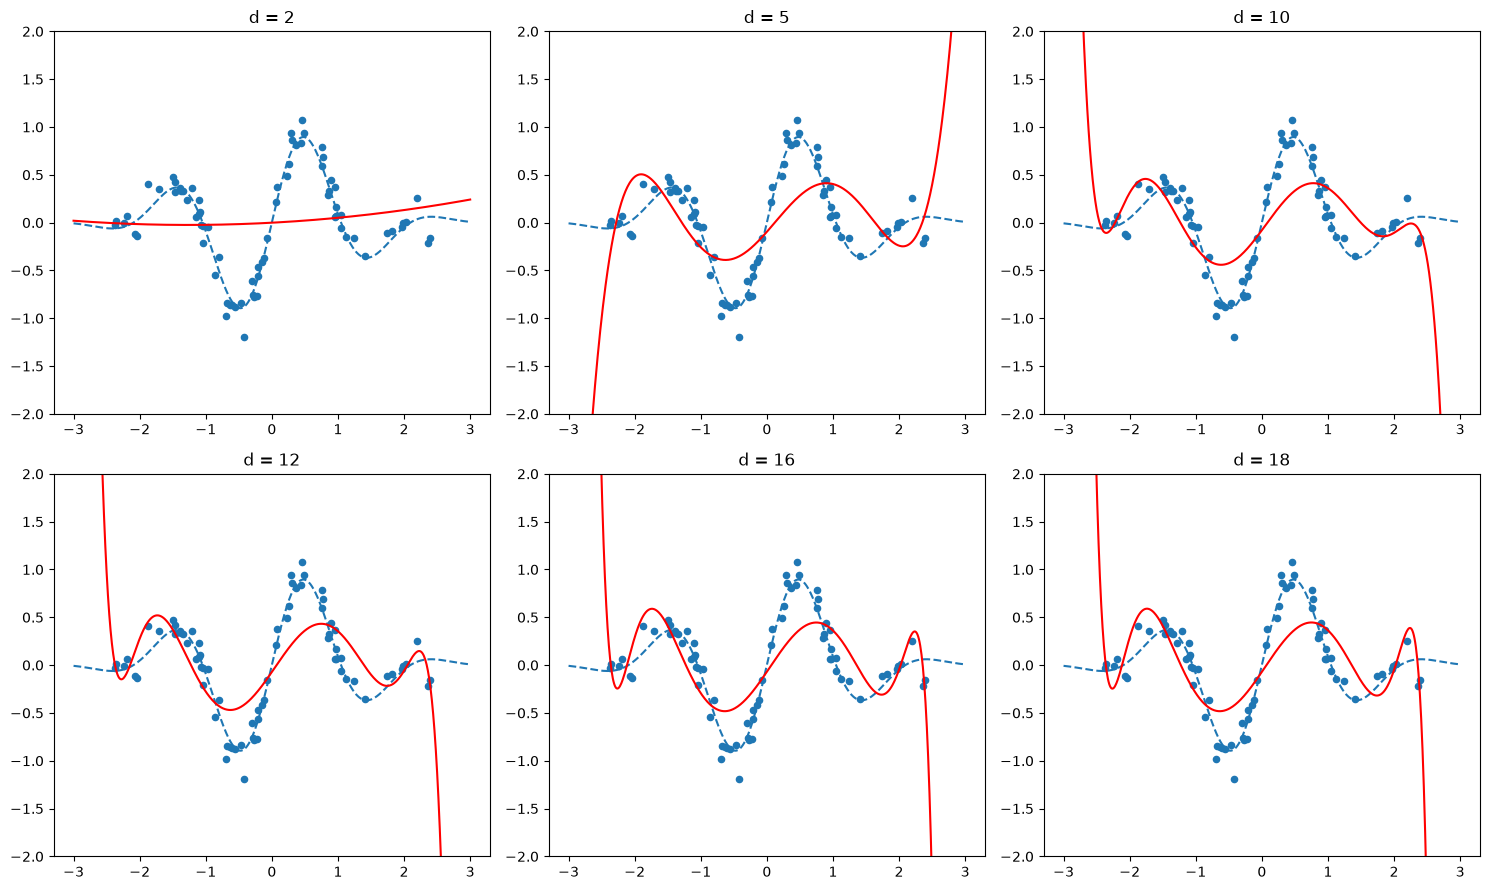

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
d_list = [2, 5, 10, 12, 16, 18]


for n, d in enumerate(d_list):
    i = n%3
    j = n//3
    
    pipe_pr = Pipeline([
    ('poly', PolynomialFeatures(degree=d)),
    ('scale', StandardScaler()),
    ('reg', RidgeCV()),
    ])

    pipe_pr.fit(x_train.reshape(-1, 1), y_train)
    y_pr_pred = pipe_pr.predict(x.reshape(-1, 1))
    
    axes[j, i].plot(x, y, '--')
    axes[j, i].scatter(x_train, y_train, s=20)
    axes[j, i].plot(x, y_pr_pred, color="red")
    axes[j, i].set_title(f'd = {d}')
    axes[j, i].set_ylim([-2, 2])
    

fig.tight_layout()
plt.show()

## Задача 2. Предсказание растворимости молекул

Поработаем с известным датасетом [ESOL](https://www.kaggle.com/c/drug-solubility-challenge/data), содержащим данные о растворимости лекарствоподобных и других органических молекул в воде. Обычно молекулярные признаки вычисляют с помощью `rdkit` и других хемоинформатических инструментов, но в этом наборе данные уже подготовлены заранее.

In [8]:
import pandas as pd

url = "https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv"


In [9]:
df = pd.read_csv(url)
X = df.iloc[:, 2:-2]
y = df['measured log solubility in mols per litre']

Разделите данные на обучающую и тестовую выборки. Обучите три модели: kNN-регрессию, линейную регрессию и полиномиальную регрессию с `RidgeCV`. Не забудьте стандартизовать признаки. Приблизительно подберите число соседей и степень полинома по результатам на **обучающей** выборке. Сравните качество моделей на тестовой выборке с метрикой $R^2$.

In [10]:
# your code here
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import r2_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)


In [11]:
def train_model(pipeline, X_train, y_train):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_train)
    r2 = r2_score(y_train, y_pred)
    mae = MAE(y_train, y_pred)

    return (r2, mae)


k_list = [i*2 for i in range(1, 10)]


r2_scores = []
mae_scores = []
for k in k_list:
    pipe_KNN = Pipeline([
    ('scale', StandardScaler()),
    ('reg', kNN(n_neighbors=k))
    ])
    
    r2, mae = train_model(pipe_KNN, X_train, y_train)
    r2_scores.append(r2)
    mae_scores.append(mae)


pd.DataFrame([r2_scores, mae_scores], index=["r2", "MAE"], columns=k_list)


,2,4,6,8,10,12,14,16,18
r2,0.936855,0.889561,0.848586,0.840510,0.826171,0.815239,0.803935,0.795828,0.789123
MAE,0.370974,0.513433,0.598259,0.622161,0.657025,0.676758,0.695529,0.709074,0.719418


In [12]:
d_list = [i*2 for i in range(1, 10)]


r2_scores = []
mae_scores = []
for d in d_list:
    pipe_pr = Pipeline([
    ('poly', PolynomialFeatures(degree=d)),
    ('scale', StandardScaler()),
    ('reg', RidgeCV()),
    ])

    r2, mae = train_model(pipe_pr, X_train, y_train)
    r2_scores.append(r2)
    mae_scores.append(mae)


pd.DataFrame([r2_scores, mae_scores], index=["r2", "MAE"], columns=d_list)

,2,4,6,8,10,12,14,16,18
r2,0.789345,0.820124,0.834031,0.843749,0.849317,0.852334,0.854147,0.855327,0.856159
MAE,0.748824,0.689908,0.657441,0.631471,0.614308,0.603867,0.596758,0.592088,0.589066


In [13]:
pipe_lr = Pipeline([
    ('scale', StandardScaler()),
    ('reg', LinReg())
    ])

train_model(pipe_lr, X_train, y_train)

(0.6819748009787578, 0.9197247938378312)

In [14]:
best_k = 4
best_d = 8

models = {
    "kNN": Pipeline([
        ("scale", StandardScaler()),
        ("reg", kNN(n_neighbors=best_k)),
    ]),
    "LinearRegression": Pipeline([
        ("scale", StandardScaler()),
        ("reg", LinReg()),
    ]),
    "Poly + RidgeCV": Pipeline([
        ("poly", PolynomialFeatures(degree=best_d)),
        ("scale", StandardScaler()),
        ("reg", RidgeCV()),
    ]),
}

test_r2 = {}
for name, model in models.items():
  model.fit(X_train, y_train)
  y_test_pred = model.predict(X_test)
  test_r2[name] = r2_score(y_test, y_test_pred)

pd.Series(test_r2, name="Test R2")

kNN                 0.800302
LinearRegression    0.694374
Poly + RidgeCV     -3.064643
Name: Test R2, dtype: float64